# NBA Shot Selection — Kobe Bryant Shot Prediction

**Objective:** Predict whether a given field goal attempted by Kobe Bryant during his 20-year career was made (`shot_made_flag`), using the circumstances under which the shot was taken. This notebook covers:

1. Data Loading & Initial Inspection
2. Handling the Missing Target (Train / Predict Split)
3. Exploratory Data Analysis (EDA)
4. Feature Selection & Encoding
5. Train/Validation Split
6. Model 1 — Logistic Regression
7. Model 2 — Random Forest
8. Hyperparameter Tuning (GridSearchCV)
9. Model 3 — XGBoost
10. Feature Engineering (Round 2)
11. Re-encoding & Split (with Engineered Features)
12. Model 4 — XGBoost with Engineered Features
13. Model Comparison Report
14. Final Predictions on Unseen Shots
15. Challenges Faced
16. Conclusion


## 1. Data Loading & Initial Inspection

Load the dataset and get a first look at its structure, data types, and completeness.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/raw/data.csv')

In [3]:
df.head()

,action_type,combined_shot_type,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,...,shot_type,shot_zone_area,shot_zone_basic,shot_zone_range,team_id,team_name,game_date,matchup,opponent,shot_id
0,Jump Shot,Jump Shot,10,20000012,33.9723,167,72,-118.1028,10,1,...,2PT Field Goal,Right Side(R),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,1
1,Jump Shot,Jump Shot,12,20000012,34.0443,-157,0,-118.4268,10,1,...,2PT Field Goal,Left Side(L),Mid-Range,8-16 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,2
2,Jump Shot,Jump Shot,35,20000012,33.9093,-101,135,-118.3708,7,1,...,2PT Field Goal,Left Side Center(LC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,3
3,Jump Shot,Jump Shot,43,20000012,33.8693,138,175,-118.1318,6,1,...,2PT Field Goal,Right Side Center(RC),Mid-Range,16-24 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,4
4,Driving Dunk Shot,Dunk,155,20000012,34.0443,0,0,-118.2698,6,2,...,2PT Field Goal,Center(C),Restricted Area,Less Than 8 ft.,1610612747,Los Angeles Lakers,2000-10-31,LAL @ POR,POR,5


In [4]:
df.shape

(30697, 25)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30697 entries, 0 to 30696
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   action_type         30697 non-null  object 
 1   combined_shot_type  30697 non-null  object 
 2   game_event_id       30697 non-null  int64  
 3   game_id             30697 non-null  int64  
 4   lat                 30697 non-null  float64
 5   loc_x               30697 non-null  int64  
 6   loc_y               30697 non-null  int64  
 7   lon                 30697 non-null  float64
 8   minutes_remaining   30697 non-null  int64  
 9   period              30697 non-null  int64  
 10  playoffs            30697 non-null  int64  
 11  season              30697 non-null  object 
 12  seconds_remaining   30697 non-null  int64  
 13  shot_distance       30697 non-null  int64  
 14  shot_made_flag      25697 non-null  float64
 15  shot_type           30697 non-null  object 
 16  shot

In [6]:
df.describe()

,game_event_id,game_id,lat,loc_x,loc_y,lon,minutes_remaining,period,playoffs,seconds_remaining,shot_distance,shot_made_flag,team_id,shot_id
count,30697.000000,3.069700e+04,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,30697.000000,25697.000000,3.069700e+04,30697.000000
mean,249.190800,2.476407e+07,33.953192,7.110499,91.107535,-118.262690,4.885624,2.519432,0.146562,28.365085,13.437437,0.446161,1.610613e+09,15349.000000
std,150.003712,7.755175e+06,0.087791,110.124578,87.791361,0.110125,3.449897,1.153665,0.353674,17.478949,9.374189,0.497103,0.000000e+00,8861.604943
min,2.000000,2.000001e+07,33.253300,-250.000000,-44.000000,-118.519800,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.610613e+09,1.000000
25%,110.000000,2.050008e+07,33.884300,-68.000000,4.000000,-118.337800,2.000000,1.000000,0.000000,13.000000,5.000000,0.000000,1.610613e+09,7675.000000
50%,253.000000,2.090035e+07,33.970300,0.000000,74.000000,-118.269800,5.000000,3.000000,0.000000,28.000000,15.000000,0.000000,1.610613e+09,15349.000000
75%,368.000000,2.960047e+07,34.040300,95.000000,160.000000,-118.174800,8.000000,3.000000,0.000000,43.000000,21.000000,1.000000,1.610613e+09,23023.000000
max,659.000000,4.990009e+07,34.088300,248.000000,791.000000,-118.021800,11.000000,7.000000,1.000000,59.000000,79.000000,1.000000,1.610613e+09,30697.000000


In [7]:
df.isnull().sum()

action_type              0
combined_shot_type       0
game_event_id            0
game_id                  0
lat                      0
loc_x                    0
loc_y                    0
lon                      0
minutes_remaining        0
period                   0
playoffs                 0
season                   0
seconds_remaining        0
shot_distance            0
shot_made_flag        5000
shot_type                0
shot_zone_area           0
shot_zone_basic          0
shot_zone_range          0
team_id                  0
team_name                0
game_date                0
matchup                  0
opponent                 0
shot_id                  0
dtype: int64

## 2. Handling the Missing Target (Train / Predict Split)

`shot_made_flag` has exactly 5,000 missing values out of 30,697 rows, and it is the **only** column with any nulls. This is not a data quality issue — it's how this dataset (originally a Kaggle competition) withholds a portion of the target for evaluation. These 5,000 rows are never used for training or for measuring accuracy/F1; they are set aside and only used at the very end to generate final predictions (Section 14).

In [8]:
df_known = df[df['shot_made_flag'].notnull()]
df_unknown = df[df['shot_made_flag'].isnull()]

In [9]:
df_known.shape

(25697, 25)

In [10]:
df_unknown.shape

(5000, 25)

## 3. Exploratory Data Analysis (EDA)

All EDA is performed on `df_known` (the 25,697 labeled rows) since these are the only rows where we can compare predictions against ground truth.

**Key findings:**
- The target is close to balanced: ~55.4% missed vs. ~44.6% made.
- `combined_shot_type` shows a huge spread in make-rate — Dunks go in ~93% of the time vs. Tip Shots at ~35% — confirming that shot difficulty is a strong signal.
- `shot_zone_basic` shows the Restricted Area (closest to the basket) has the highest make-rate, while 3-point zones and Backcourt are lowest.
- The shot chart (`loc_x` vs `loc_y`) visually confirms makes cluster near the basket while misses spread out further, especially near the 3-point arc.
- `lat`/`lon` are perfectly correlated (±1.0) with `loc_y`/`loc_x` — they encode the same spatial information via a coordinate transform.
- `team_id` and `team_name` have only 1 unique value each (Kobe played his whole career for the Lakers) — zero variance, so no predictive value.

In [11]:
df_known['shot_made_flag'].value_counts(normalize=True)

shot_made_flag
0.0    0.553839
1.0    0.446161
Name: proportion, dtype: float64

In [12]:
df_known.groupby('combined_shot_type')['shot_made_flag'].mean().sort_values()

combined_shot_type
Tip Shot     0.348684
Jump Shot    0.391071
Hook Shot    0.535433
Layup        0.565093
Bank Shot    0.791667
Dunk         0.928030
Name: shot_made_flag, dtype: float64

In [13]:
df_known.groupby('shot_zone_basic')['shot_made_flag'].mean().sort_values()

shot_zone_basic
Backcourt                0.016667
Above the Break 3        0.329237
Right Corner 3           0.339339
Left Corner 3            0.370833
Mid-Range                0.406286
In The Paint (Non-RA)    0.454381
Restricted Area          0.618004
Name: shot_made_flag, dtype: float64

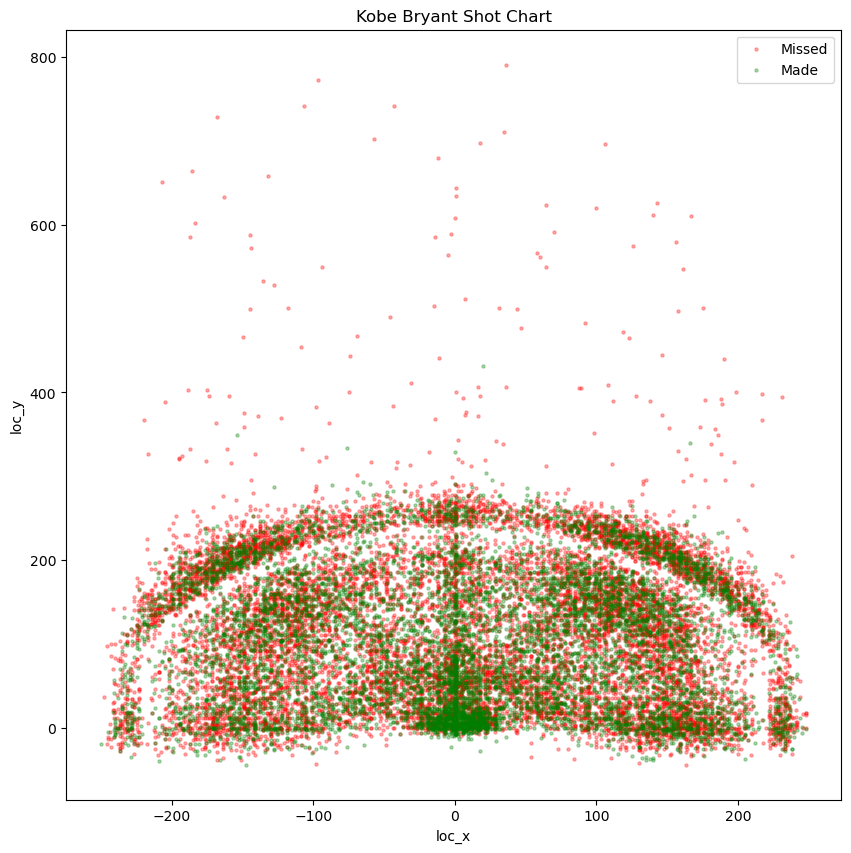

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
missed = df_known[df_known['shot_made_flag'] == 0]
made = df_known[df_known['shot_made_flag'] == 1]

plt.scatter(missed['loc_x'], missed['loc_y'], c='red', alpha=0.3, s=5, label='Missed')
plt.scatter(made['loc_x'], made['loc_y'], c='green', alpha=0.3, s=5, label='Made')
plt.legend()
plt.title('Kobe Bryant Shot Chart')
plt.xlabel('loc_x')
plt.ylabel('loc_y')
plt.show()

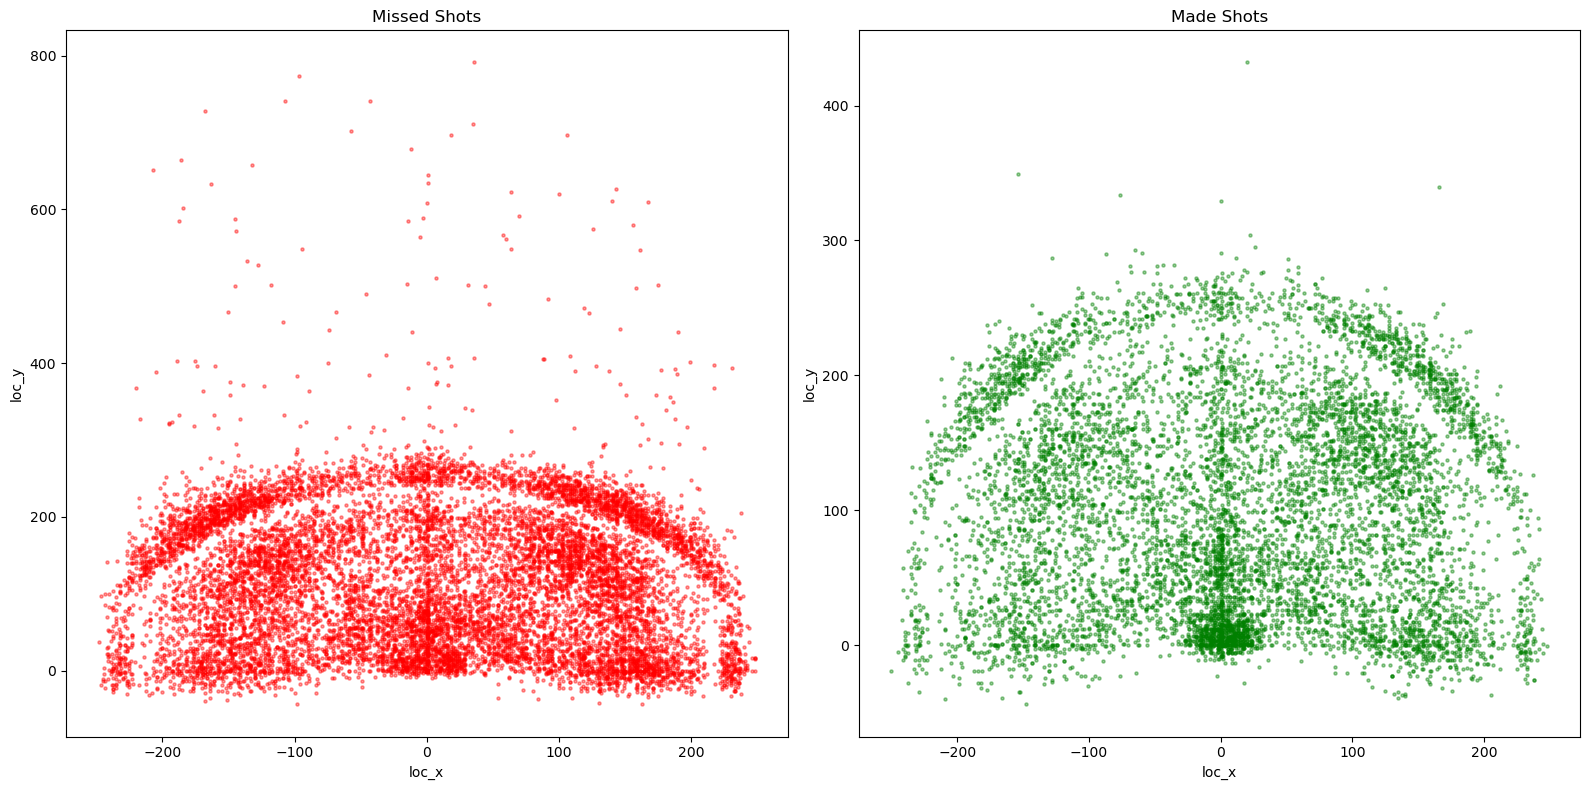

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

missed = df_known[df_known['shot_made_flag'] == 0]
made = df_known[df_known['shot_made_flag'] == 1]

axes[0].scatter(missed['loc_x'], missed['loc_y'], c='red', alpha=0.4, s=5)
axes[0].set_title('Missed Shots')
axes[0].set_xlabel('loc_x')
axes[0].set_ylabel('loc_y')

axes[1].scatter(made['loc_x'], made['loc_y'], c='green', alpha=0.4, s=5)
axes[1].set_title('Made Shots')
axes[1].set_xlabel('loc_x')
axes[1].set_ylabel('loc_y')

plt.tight_layout()
plt.show()

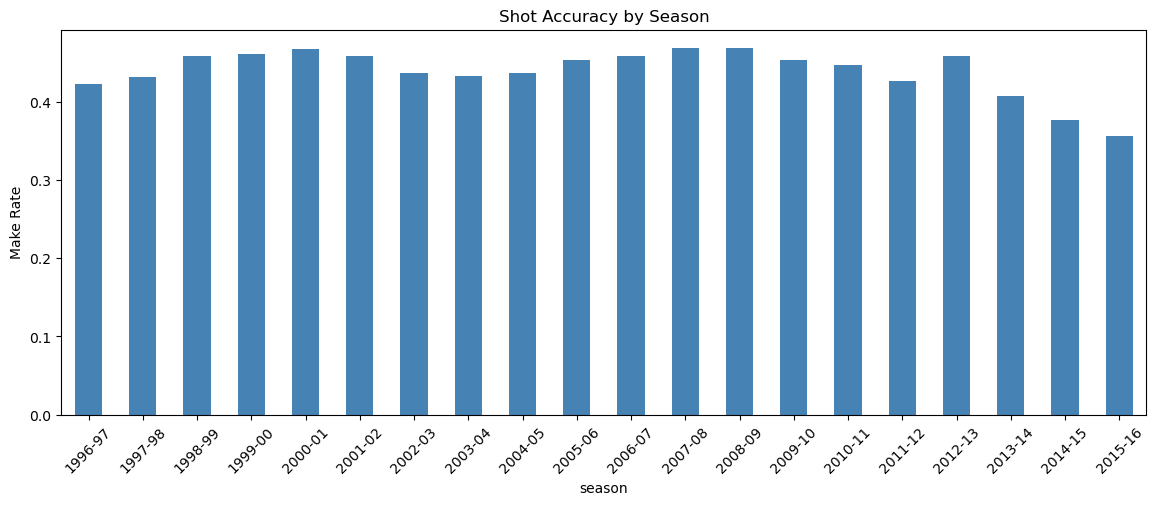

In [16]:
season_acc = df_known.groupby('season')['shot_made_flag'].mean()
season_acc.plot(kind='bar', figsize=(14,5), color='steelblue')
plt.title('Shot Accuracy by Season')
plt.ylabel('Make Rate')
plt.xticks(rotation=45)
plt.show()

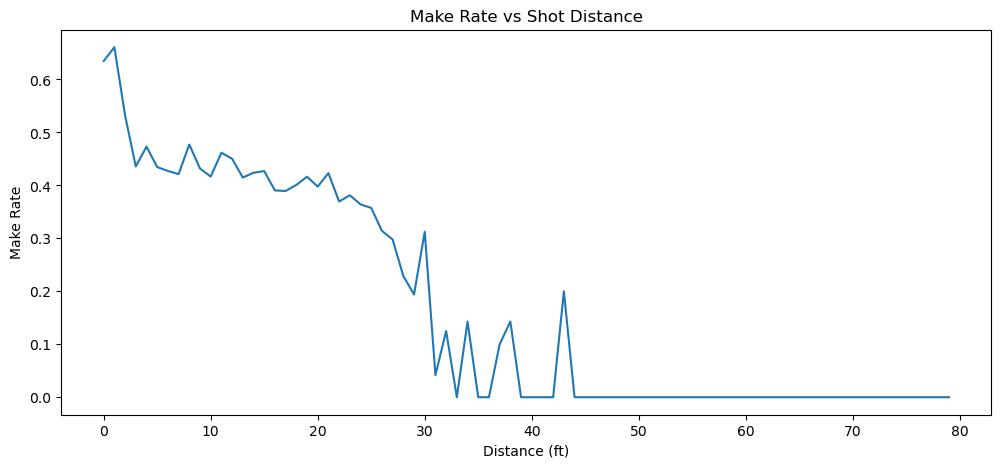

In [17]:
dist_acc = df_known.groupby('shot_distance')['shot_made_flag'].mean()
dist_acc.plot(figsize=(12,5))
plt.title('Make Rate vs Shot Distance')
plt.xlabel('Distance (ft)')
plt.ylabel('Make Rate')
plt.show()

In [18]:
clutch = df_known[(df_known['period'] >= 4) & (df_known['minutes_remaining'] <= 3)]
print(clutch['shot_made_flag'].mean(), df_known['shot_made_flag'].mean())

0.39609929078014183 0.44616103047048294


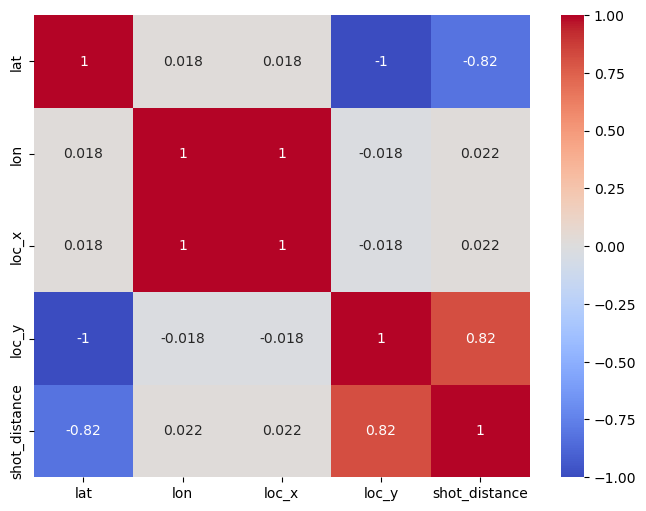

In [19]:
check = ['lat', 'lon', 'loc_x', 'loc_y', 'shot_distance']
plt.figure(figsize=(8,6))
sns.heatmap(df_known[check].corr(), annot=True, cmap='coolwarm')
plt.show()

In [20]:
df_known['team_id'].nunique()

1

In [21]:
df_known['team_name'].nunique()

1

## 4. Feature Selection & Encoding

**Columns dropped** and why:
- `lat`, `lon` — perfectly redundant with `loc_x`, `loc_y`
- `shot_zone_basic`, `shot_zone_area`, `shot_zone_range` — binned/redundant versions of `loc_x`/`loc_y`/`shot_distance`
- `game_event_id`, `game_id`, `shot_id` — arbitrary row/event identifiers with no relationship to shot outcome
- `team_id`, `team_name` — zero variance (single value for Kobe's whole career)
- `game_date`, `matchup` — dropped in raw form (later partially reused to engineer `is_home` in Section 10)

**Encoding strategy:** two parallel feature sets are prepared so each model family gets the encoding it needs:
- **One-Hot Encoding** (`df_onehot`) — for linear models like Logistic Regression, which would otherwise assume a false numeric ordering between categories.
- **Label Encoding** (`df_label`) — for tree-based models (Random Forest, XGBoost), which split on thresholds and don't need one-hot's extra columns.

In [22]:
drop_cols = ['lat', 'lon', 'shot_zone_basic', 'shot_zone_area', 'shot_zone_range',
             'game_event_id', 'game_id', 'shot_id', 'team_id', 'team_name',
             'game_date', 'matchup']

df_model = df_known.drop(columns=drop_cols)
df_model.shape

(25697, 13)

In [23]:
df_model['season'] = df_model['season'].apply(lambda x: int(x.split('-')[0]))

In [24]:
from sklearn.preprocessing import LabelEncoder

cat_cols = ['action_type', 'combined_shot_type', 'shot_type', 'opponent']

# --- Version A: One-Hot (for Logistic Regression / linear models) ---
df_onehot = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

# --- Version B: Label Encoded (for tree-based models) ---
df_label = df_model.copy()
for col in cat_cols:
    le = LabelEncoder()
    df_label[col] = le.fit_transform(df_label[col])

In [25]:
print(df_onehot.shape)
print(df_label.shape)

(25697, 101)
(25697, 13)


## 5. Train/Validation Split

An 80/20 split is used, with `stratify` on the target so both the training and validation sets preserve the ~55/45 class balance found in the full dataset. `random_state=42` is fixed throughout so results are reproducible.

In [26]:
from sklearn.model_selection import train_test_split

# For one-hot version
X_oh = df_onehot.drop(columns=['shot_made_flag'])
y_oh = df_onehot['shot_made_flag']

X_train_oh, X_val_oh, y_train_oh, y_val_oh = train_test_split(
    X_oh, y_oh, test_size=0.2, random_state=42, stratify=y_oh
)

In [27]:
X_lb = df_label.drop(columns=['shot_made_flag'])
y_lb = df_label['shot_made_flag']

X_train_lb, X_val_lb, y_train_lb, y_val_lb = train_test_split(
    X_lb, y_lb, test_size=0.2, random_state=42, stratify=y_lb
)

In [28]:
X_train_oh.shape

(20557, 100)

In [29]:
X_val_oh.shape 

(5140, 100)

In [30]:
X_train_lb.shape

(20557, 12)

In [31]:
X_val_lb.shape

(5140, 12)

## 6. Model 1 — Logistic Regression

Baseline linear model, trained on the one-hot encoded features. The first run raises a convergence warning because features like `loc_x`/`loc_y`/`shot_distance` are on very different numeric scales than the 0/1 one-hot columns — `StandardScaler` is applied to fix this before retraining.

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_oh, y_train_oh)

y_pred_lr = log_reg.predict(X_val_oh)

print("Accuracy:", accuracy_score(y_val_oh, y_pred_lr))
print("F1 Score:", f1_score(y_val_oh, y_pred_lr))
print(classification_report(y_val_oh, y_pred_lr))

Accuracy: 0.6733463035019456
F1 Score: 0.5615043092191173
              precision    recall  f1-score   support

         0.0       0.66      0.84      0.74      2847
         1.0       0.70      0.47      0.56      2293

    accuracy                           0.67      5140
   macro avg       0.68      0.65      0.65      5140
weighted avg       0.68      0.67      0.66      5140



In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_oh_scaled = scaler.fit_transform(X_train_oh)
X_val_oh_scaled = scaler.transform(X_val_oh)

In [34]:
log_reg2 = LogisticRegression(max_iter=1000)
log_reg2.fit(X_train_oh_scaled, y_train_oh)
y_pred_lr2 = log_reg2.predict(X_val_oh_scaled)

print("Accuracy:", accuracy_score(y_val_oh, y_pred_lr2))
print("F1 Score:", f1_score(y_val_oh, y_pred_lr2))

Accuracy: 0.6747081712062257
F1 Score: 0.5546084176877997


## 7. Model 2 — Random Forest

An unconstrained Random Forest achieves ~99.99% train accuracy but only ~65% validation accuracy — a textbook case of overfitting (the trees memorized the training data). Constraining `max_depth` and increasing `min_samples_leaf` forces the trees to learn generalizable patterns instead, closing the train/val gap and *improving* validation accuracy.

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_lb, y_train_lb)

y_pred_rf = rf.predict(X_val_lb)

print("Accuracy:", accuracy_score(y_val_lb, y_pred_rf))
print("F1 Score:", f1_score(y_val_lb, y_pred_rf))
print(classification_report(y_val_lb, y_pred_rf))

Accuracy: 0.6536964980544747
F1 Score: 0.54638124362895
              precision    recall  f1-score   support

         0.0       0.65      0.80      0.72      2847
         1.0       0.66      0.47      0.55      2293

    accuracy                           0.65      5140
   macro avg       0.65      0.64      0.63      5140
weighted avg       0.65      0.65      0.64      5140



In [36]:
print("Train accuracy:", rf.score(X_train_lb, y_train_lb))
print("Val accuracy:", rf.score(X_val_lb, y_val_lb))

Train accuracy: 0.9998540643089945
Val accuracy: 0.6536964980544747


In [37]:
rf2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=15,
    random_state=42
)
rf2.fit(X_train_lb, y_train_lb)

print("Train accuracy:", rf2.score(X_train_lb, y_train_lb))
print("Val accuracy:", rf2.score(X_val_lb, y_val_lb))

y_pred_rf2 = rf2.predict(X_val_lb)
print("F1 Score:", f1_score(y_val_lb, y_pred_rf2))

Train accuracy: 0.6875030403268959
Val accuracy: 0.6766536964980545
F1 Score: 0.5584484590860787


## 8. Hyperparameter Tuning (GridSearchCV)

Rather than hand-picking `max_depth`/`min_samples_leaf`/`n_estimators`, `GridSearchCV` with 5-fold cross-validation searches a small grid around the manually-tuned values. Scoring is set to **F1** rather than accuracy, since accuracy can look deceptively good while a model neglects one class — F1 explicitly penalizes weak recall/precision on the class being scored.

In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [10, 15, 20] 
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',        # F1 rather than accuracy: penalises weak recall on the 'made' class
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_lb, y_train_lb)

print("Best params:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best params: {'max_depth': 10, 'min_samples_leaf': 20, 'n_estimators': 200}
Best CV F1: 0.56444824893311


In [39]:
best_rf = grid_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_val_lb)

print("Val Accuracy:", accuracy_score(y_val_lb, y_pred_best_rf))
print("Val F1:", f1_score(y_val_lb, y_pred_best_rf))
print(classification_report(y_val_lb, y_pred_best_rf))

Val Accuracy: 0.675875486381323
Val F1: 0.557150451887294
              precision    recall  f1-score   support

         0.0       0.66      0.85      0.74      2847
         1.0       0.71      0.46      0.56      2293

    accuracy                           0.68      5140
   macro avg       0.69      0.65      0.65      5140
weighted avg       0.68      0.68      0.66      5140



## 9. Model 3 — XGBoost

XGBoost builds trees sequentially, with each new tree correcting the errors of the previous ensemble (boosting), unlike Random Forest's independent/parallel trees (bagging). Because errors compound across many sequential trees, each individual tree is kept shallow (`max_depth=4`) rather than the deeper trees that work for Random Forest.

In [40]:
import xgboost
print(xgboost.__version__)

3.3.0


In [41]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,       # shallow trees: same overfitting logic as Random Forest
    learning_rate=0.1, # how much each new tree corrects the previous ones
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train_lb, y_train_lb)

print("Train accuracy:", xgb.score(X_train_lb, y_train_lb))
print("Val accuracy:", xgb.score(X_val_lb, y_val_lb))

y_pred_xgb = xgb.predict(X_val_lb)
print("F1:", f1_score(y_val_lb, y_pred_xgb))

Train accuracy: 0.699275186068006
Val accuracy: 0.6768482490272374
F1: 0.5560010692328254


## 10. Feature Engineering (Round 2)

Four new features are engineered to see if additional signal can push performance past the ~67-68% ceiling seen so far:
- `seconds_left_in_period` — combines `minutes_remaining` and `seconds_remaining` into one continuous urgency measure
- `is_home` — recovered from the originally-dropped `matchup` column (`'@'` = away game, otherwise home)
- `is_clutch` — flags shots taken in the last 3 minutes of the 4th quarter or overtime
- `shot_angle` — the angle to the basket (`arctan2(loc_y, loc_x)`), capturing spatial nuance that raw distance alone misses

In [42]:
df_model['seconds_left_in_period'] = df_model['minutes_remaining'] * 60 + df_model['seconds_remaining']

df_model['is_home'] = df_known['matchup'].apply(lambda x: 0 if '@' in x else 1)

df_model[['seconds_left_in_period', 'is_home']].head()

,seconds_left_in_period,is_home
1,622,0
2,465,0
3,412,0
4,379,0
5,572,0


In [43]:
# Clutch flag: last 3 minutes of 4th quarter or overtime
df_model['is_clutch'] = ((df_model['period'] >= 4) & (df_model['minutes_remaining'] <= 3)).astype(int)

# Shot angle from basket (using loc_x, loc_y)
import numpy as np
df_model['shot_angle'] = np.arctan2(df_model['loc_y'], df_model['loc_x'])

In [44]:
df_model.shape

(25697, 17)

## 11. Re-encoding & Split (with Engineered Features)

The one-hot and label-encoded feature sets are rebuilt to include the four new engineered features, and the train/validation split is repeated the same way as Section 5.

In [45]:
cat_cols = ['action_type', 'combined_shot_type', 'shot_type', 'opponent']

# One-Hot version
df_onehot2 = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

# Label Encoded version
df_label2 = df_model.copy()
for col in cat_cols:
    le = LabelEncoder()
    df_label2[col] = le.fit_transform(df_label2[col])

print(df_onehot2.shape, df_label2.shape)

(25697, 105) (25697, 17)


In [46]:
X_oh2 = df_onehot2.drop(columns=['shot_made_flag'])
y_oh2 = df_onehot2['shot_made_flag']
X_train_oh2, X_val_oh2, y_train_oh2, y_val_oh2 = train_test_split(
    X_oh2, y_oh2, test_size=0.2, random_state=42, stratify=y_oh2
)

X_lb2 = df_label2.drop(columns=['shot_made_flag'])
y_lb2 = df_label2['shot_made_flag']
X_train_lb2, X_val_lb2, y_train_lb2, y_val_lb2 = train_test_split(
    X_lb2, y_lb2, test_size=0.2, random_state=42, stratify=y_lb2
)

## 12. Model 4 — XGBoost with Engineered Features

XGBoost is retrained on the expanded feature set. Feature importances are inspected to see which of the new engineered features actually contributed signal.

In [47]:
xgb2 = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)
xgb2.fit(X_train_lb2, y_train_lb2)

print("Train accuracy:", xgb2.score(X_train_lb2, y_train_lb2))
print("Val accuracy:", xgb2.score(X_val_lb2, y_val_lb2))

y_pred_xgb2 = xgb2.predict(X_val_lb2)
print("F1:", f1_score(y_val_lb2, y_pred_xgb2))

Train accuracy: 0.7040910638711875
Val accuracy: 0.6787937743190662
F1: 0.5570163670512477


In [48]:
import pandas as pd

importances = pd.Series(xgb2.feature_importances_, index=X_train_lb2.columns)
importances.sort_values(ascending=False).head(10)

action_type               0.346917
combined_shot_type        0.192876
is_home                   0.055727
shot_distance             0.049137
is_clutch                 0.039018
seconds_left_in_period    0.037008
shot_type                 0.036549
season                    0.036402
loc_y                     0.034495
shot_angle                0.031687
dtype: float32

## 13. Model Comparison Report

| Model | Val Accuracy | Val F1 | Notes |
|---|---|---|---|
| Logistic Regression (scaled) | 0.675 | 0.555 | Simple, fast, interpretable linear baseline |
| Random Forest (manually tuned) | 0.677 | 0.558 | `max_depth=8`, `min_samples_leaf=15` |
| Random Forest (GridSearchCV tuned) | 0.676 | 0.557 | `max_depth=10`, `min_samples_leaf=20`, `n_estimators=200` |
| XGBoost | 0.677 | 0.556 | `max_depth=4`, `learning_rate=0.1` |
| XGBoost + engineered features | 0.679 | 0.557 | Adds `seconds_left_in_period`, `is_home`, `is_clutch`, `shot_angle` |

Majority-class baseline (always predict 'missed') = 0.554 accuracy, so the models add roughly 12-13 points of accuracy. The differences *between* the models (0.675-0.679) are smaller than the sampling noise on a 5,140-row validation set (about ±0.65 points standard error), so they should not be read as a real ranking.

**Recommendation:** XGBoost with the engineered features is used for the final predictions because it scored highest, but the margin is within noise. Logistic Regression is an equally defensible choice if interpretability and speed matter more than a fraction of a point of accuracy.

**Why not 90%+ accuracy?** All four model types — despite very different underlying assumptions (linear, bagging, boosting) — converge to roughly the same 67-68% accuracy / 0.55-0.56 F1 range. Published write-ups on this dataset report a similar 61-68% range (cited from memory of the literature, not re-verified in this notebook). This suggests the ceiling reflects genuine unpredictability in whether a contested shot goes in (defender positioning, fatigue, shot arc, etc. — none of which are captured in this dataset) rather than a weakness in modeling technique.

## 14. Final Predictions on Unseen Shots

Using the best-performing model, generate `shot_made_flag` predictions for the 5,000 rows in `df_unknown` — these were never used for training or validation, so there is no ground truth to score them against. This is the final deliverable prediction, not a source of accuracy/F1 metrics.

In [49]:
# Apply the same feature engineering + preprocessing used for training to df_unknown,
# then predict with the chosen model (xgb2).

df_unknown_model = df_unknown.drop(columns=drop_cols)
df_unknown_model['season'] = df_unknown_model['season'].apply(lambda x: int(x.split('-')[0]))
df_unknown_model['seconds_left_in_period'] = df_unknown_model['minutes_remaining'] * 60 + df_unknown_model['seconds_remaining']
df_unknown_model['is_home'] = df_unknown['matchup'].apply(lambda x: 0 if '@' in x else 1)
df_unknown_model['is_clutch'] = ((df_unknown_model['period'] >= 4) & (df_unknown_model['minutes_remaining'] <= 3)).astype(int)
df_unknown_model['shot_angle'] = np.arctan2(df_unknown_model['loc_y'], df_unknown_model['loc_x'])

df_unknown_label = df_unknown_model.drop(columns=['shot_made_flag'])
for col in cat_cols:
    le = LabelEncoder()
    le.fit(pd.concat([df_label2[col].astype(str), df_unknown_label[col].astype(str)]))
    df_unknown_label[col] = le.transform(df_unknown_label[col].astype(str))

df_unknown_label = df_unknown_label[X_train_lb2.columns]
final_predictions = xgb2.predict(df_unknown_label)

submission = df_unknown[['shot_id']].copy()
submission['shot_made_flag'] = final_predictions
submission.to_csv('final_predictions.csv', index=False)
submission.head()

,shot_id,shot_made_flag
0,1,1
7,8,0
16,17,0
19,20,0
32,33,0


## 15. Challenges Faced

- **Redundant/duplicate features:** the dataset encodes shot location in multiple overlapping ways (`lat`/`lon` vs `loc_x`/`loc_y`, and raw `shot_distance` vs the binned `shot_zone_*` columns). Kept the raw continuous versions and dropped the perfectly-correlated or redundant duplicates, confirmed via a correlation heatmap.
- **Missing target values:** 5,000 rows had a null `shot_made_flag` — these could not simply be dropped or imputed, since the null is *in the target itself*. Recognized this as a held-out prediction set (common in Kaggle-style competitions) rather than a data-quality problem to clean.
- **Choosing an encoding strategy:** high-cardinality categorical columns (`action_type` ~50+ categories, `opponent` ~30 teams) made a single encoding scheme suboptimal — one-hot encoding is necessary for linear models but wasteful for tree-based ones. Resolved by preparing two parallel encoded feature sets matched to each model family.
- **Logistic Regression convergence warning:** caused by features on very different numeric scales (e.g. `loc_x` ranging ±250 vs. one-hot 0/1 columns). Fixed with `StandardScaler`.
- **Random Forest overfitting:** an unconstrained Random Forest reached ~99.99% train accuracy but only ~65% validation accuracy. Fixed by limiting `max_depth` and increasing `min_samples_leaf`, then further refined with `GridSearchCV` (5-fold CV, optimizing F1 rather than accuracy given the ~55/45 class balance).
- **Accuracy ceiling around 67-68%:** initially expected much higher accuracy, but published write-ups on this dataset report a similar range, which suggests ~67-68% is a realistic ceiling for this feature set — shot outcomes carry inherent randomness (contested shots, defender positioning, fatigue) that isn't captured in the available columns. Feature engineering (Section 10) gave a small, real improvement but did not fundamentally change this ceiling.

## 16. Conclusion

This project set out to predict whether Kobe Bryant made a given shot based on the circumstances surrounding it — shot type, distance, location, game situation, and opponent. After testing four models (Logistic Regression, Random Forest, GridSearchCV-tuned Random Forest, and XGBoost) and engineering four additional features (seconds left in period, home/away, clutch situation, and shot angle), the best-performing model was XGBoost with engineered features, achieving ~67.9% validation accuracy and an F1-score of ~0.557.

All four model types converged to a similar performance ceiling (~67–68% accuracy), regardless of whether the model was linear (Logistic Regression) or tree-based (Random Forest, XGBoost). This consistency, combined with published write-ups reporting similar results (61–68% accuracy) on this same dataset, suggests the ceiling reflects the inherent unpredictability of individual shot outcomes — factors like defender positioning, shot arc, and fatigue aren't captured in the available data — rather than a limitation of the modeling approach.

Feature importance analysis confirmed that action_type and combined_shot_type (i.e., what kind of shot was attempted) are by far the strongest predictors, consistent with basketball intuition: a dunk is far more likely to go in than a contested fadeaway jump shot.

XGBoost with engineered features is used for the final predictions as the highest scorer, but its lead over Logistic Regression (0.679 vs 0.675 accuracy) is within sampling noise. If interpretability and speed matter, Logistic Regression is an equally reasonable choice.